# NB Pipeline explanatory notebooks
## Notebook 2: Negative Binomial Model

The statistical model chosen to model clonotype counts is the Negative Binomial Distribution. In this notebook we will justify the choice of this distribution as well as the corrections made to it using biological considerations that arose in the EDA phase of section 1. We validate the model using simulations.

The objectgive of the pipeline is to determine which patient clonotypes are non-neutral. This is done by testing them agains a **null model** or **null hypothesis**, which we establish using **healthy donors**. In the literature, the most common way to establish a **null model** is using technical replicates from which the sampling noise can be determined, allowing to distinghish what is biological non-neutrality. Why use donors instead of replicates?
* `Resource/Funding contrains`: Technical replicates are expensive and not always a viable option due to resource limiation, as is our case. This would put our pipeline is a graceful spot with respect to other T-cell dynamics methdologies. All RNA-seq based methods rely on technical replicates for noise estiamtion, and even though some of them give the option to perfor analysis without them, they do specificallyt adress the propblems that arise from not using them. Our pipeline does adress them.
* `Bilological considerations`: There is also a biological argument to not use technical replicates (**REFERENCE**), or rather, to use healthy donors. Tehcnical replicates come from the patients own samples, which are expected to have more uderlying non-neutrality than a healthy person. During the computation of the sample noise, part of the genuine biology happening in the clonotype trajectotries can get confounded with technical noise, obscuring the detection of neutral clonotypes. By using healthy donors as the null baseline, we are asking a fundamentally different question for the null: How do healthy T-cell dynamics look like? 

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from tcr_pipeline.normalization import tmm_normalize
from tcr_pipeline.data_io import list_subjects, load_group, load_subject, sample_qc, drop_failed_samples
from tcr_pipeline import nb_glm as nb

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

DONOR_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
GREY, INK = '#8a8984', '#3d3c39'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': GREY, 'axes.labelcolor': INK, 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'lines.linewidth': 1.6, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9.5, 'axes.titlesize': 10})


#### Warning: With the attached TMM factor, the data frames can be expensive in memory

In [2]:
healthy_raw = load_group('donors', with_D_t=True, with_freq=True)
d_qc = nb.attach_offset(tmm_normalize(drop_failed_samples(healthy_raw, sample_qc(healthy_raw))))

DONORS = sorted(d_qc['patient'].unique())
COLOR = dict(zip(DONORS, DONOR_COLORS))
short = lambda p: p.replace('_SEQTR', '').replace('_ReSeq', '')
print(len(d_qc), 'rows,', d_qc.groupby(['patient', 'day']).ngroups, 'samples,',
      len(DONORS), 'donors')

13836210 rows, 23 samples, 6 donors


## 2.1 The model

For clone $c$ in sample $t$ of one person, the read count is

$$x_{ct} \sim \mathrm{NB}\!\left(\mu_{ct},\ \phi\right), \qquad
\log\mu_{ct} = \log L_t\ + \log\lambda_c + \beta_c s_t, \qquad s_t = \frac{t-\bar{t}}{t_{last} - t_{first}},\qquad
\mathrm{Var}(x_{ct}) = \mu_{ct} + \frac{\mu_{ct}^2}{\phi}.$$

* $\lambda_c$ is the clone's frequency. Under the **null** it is the same in every
  sample: the clone neither expands nor contracts.
* $L_t = D_t \times \text{TMM}_t$ is the sample's **offset**: its in-frame depth $D_t$
  (Section 1.1) times a TMM normalisation factor computed within the person, so that
  $\mu_{ct}$ is the expected count of a clone of frequency $\lambda_c$ in that sample. We use TMM as a robust normalization factor to correct for different sequencing depth across samples, but other normalization factor can be used.
* $\phi$ is the **dispersion**. The NB is a Poisson whose mean is itself multiplied by
  a random factor with mean 1 and squared coefficient of variation $1/\phi$. This dispersion (sometimes called overdispersion) encapsulates
  sample-to-sample noise of library preparation, RNA content per cell, amplification.
  Small $\phi$ means noisy, $\phi \to \infty$ is a Poisson (only pure sampling noise).
* $\beta_c$: the clone’s trajectory. $s_t$ is time rescaled to run over one unit across the series, so $\beta_c$ is the log fold change from the first sample to the last. For example,   $\beta_c = \log 10$ is a 10-fold expansion over the series and $\beta_c = -\log 10$ a 10-fold contraction

This is a GLM per clone: a log link, an offset, two coefficients ($\alpha_c$, $\beta_c$) and a dispersion fixed in advance.

**The null hypothesis** $H_0: \beta_c = 0$, but the meaning of “neutral” is set by the donors. Their $\phi$ is estimated with $\beta_c = 0$ for every clone, so any fluctuation healthy clones show, technical or biological, is absorbed into $\phi$. A patient clone is therefore called non-neutral when it changes more than clones in healthy people do, not merely when it is not constant. The healthy donors are assumed neutral, so $\phi$ is estimated under the null model, $\log\mu_{ct} = \log L_t + \alpha_c$, with only $\alpha_c$ fitted per clone. If a donor clone does change, the null model reads its change as extra noise and lowers $\phi$, the conservative direction. The full model with $\beta_c$ is only fitted when patients are tested.

In [3]:
#From now on we use the QC filtered data, dropping HDBR06 day 21
offsets = (d_qc.groupby(['patient', 'day'], observed=True)[['D_t', 'tmm_factor', 'lib']].first()
             .rename(columns={'lib': 'L_t'}))
offsets.index = offsets.index.set_levels(offsets.index.levels[0].map(short), level=0)
display(offsets.round({'D_t': 0, 'tmm_factor': 3, 'L_t': 0}))

D_t  tmm_factor         L_t
patient day                                  
HD106   0    21258772       0.819  17412074.0
        46   20765301       0.988  20517047.0
        82   13524147       1.082  14626523.0
        131  17575872       1.000  17575872.0
HD197   0    16537619       1.000  16537619.0
        46   15524871       1.072  16644402.0
        82   18141316       1.072  19442764.0
        131  18289621       1.083  19809672.0
HDBR01  0    10380249       1.167  12111934.0
        21   13135420       0.931  12227167.0
        42   21684876       0.747  16189793.0
        126  14117466       1.000  14117466.0
HDBR02  0     5522816       1.223   6756502.0
        48    8975122       0.895   8028455.0
        71    6840967       1.000   6840967.0
HDBR03  0    10820547       0.721   7796750.0
        21    5093101       1.080   5501255.0
        35    6584605       1.000   6584605.0
        66    5205213       1.078   5609171.0
        84    5610753       1.172   6573196.0
HDBR06  0    10824659       0.871   9424946.0
        82   11651005       0.817   9518842.0
        105  11058680       1.000  11058680.0

## 2.2 Why NB instead of Poisson?
The reason of using NB over a simpler Poisson model is the count noise is not only due to pure samplign noise, but there are other external factors that need to be taken into consideration through the dispersion $\phi$. Next, we will investigate and justify this claim using the donor data itself.

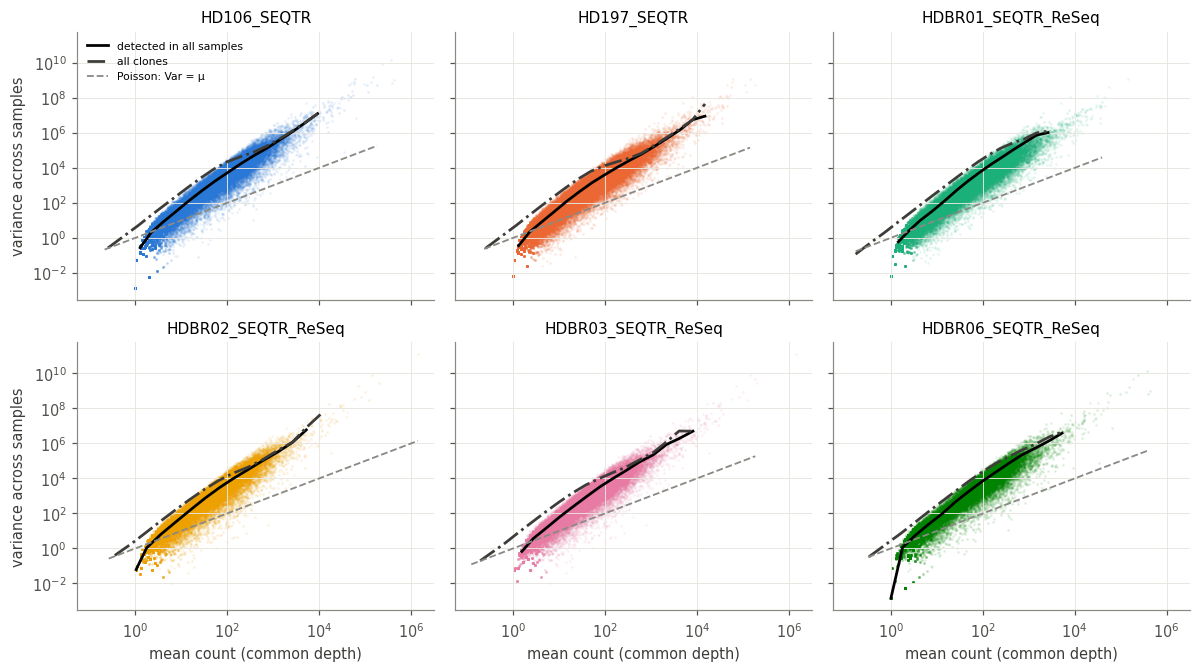

In [20]:
def mean_variance(g, mode='all', c=1, depth_col='D_t'):
    days = np.sort(g['day'].unique())
    L = g.groupby('day')[depth_col].first().reindex(days).to_numpy()
    X = (g.pivot_table(index='clono', columns='day', values='count', aggfunc='sum',
                       fill_value=0, observed=True)
           .reindex(columns=days, fill_value=0).to_numpy(float))
    det = X >= c
    if mode == 'all':
        keep = det.all(axis=1)             # detected in every sample
    elif mode == 'any':
        keep = np.ones(len(X), dtype=bool) # every clone in the table
    else:
        raise ValueError(mode)
    Y = X[keep] * (L.mean() / L)           # zeros stay zeros; they are real observations at c = 1
    return Y.mean(axis=1), Y.var(axis=1, ddof=1)

def binned(m, v, edges, min_n=20):
    k = np.digitize(m, edges)
    grp = [i for i in np.unique(k) if (k == i).sum() >= min_n]
    return (np.array([m[k == i].mean() for i in grp]),
            np.array([v[k == i].mean() for i in grp]))

ORANGE = '#d9822b'
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, p in zip(axes.ravel(), DONORS):
    g = d_qc[d_qc['patient'] == p]
    res = {mode: mean_variance(g, mode) for mode in ['all', 'any']}
    m_any = res['any'][0]
    edges = np.logspace(np.log10(m_any.min()), np.log10(m_any.max()), 22) 
    idx = rng.choice(len(m), size=min(len(m), 100_000), replace=False)
    ax.scatter(m[idx], v[idx], s=1, color=COLOR[p], alpha=0.06, rasterized=True)
    m, v = res['all']
    ax.scatter(m, v, s=1, color=COLOR[p], alpha=0.08, rasterized=True)

    for mode, col, lab, linest in [('all', "black", 'detected in all samples', "solid"),
                           ('any', INK, 'all clones', "dashdot")]:
        mb, vb = binned(*res[mode], edges)
        ax.plot(mb, vb, color=col, lw=1.8, label=lab, ls=linest)

    mm = np.logspace(np.log10(m_any.min()), np.log10(m_any.max()), 50)
    ax.plot(mm, mm, color=GREY, ls='--', lw=1.2, label='Poisson: Var = μ')
    ax.set(xscale='log', yscale='log',
           title=f"{p}")
for ax in axes[-1]:
    ax.set_xlabel('mean count (common depth)')
for ax in axes[:, 0]:
    ax.set_ylabel('variance across samples')
axes[0, 0].legend(fontsize=7, loc='upper left')
fig.tight_layout()

**What this shows.** The variance lies above the Poisson line for every donor, by up
to three orders of magnitude, and the gap widens with the mean. A Poisson model would
treat this ordinary sample-to-sample noise as real change and call most clones
non-neutral. 

## 2.3 Estimating $\phi$

$\phi$ is estimated per donor from the donor's own clones, with three ingredients.

* **1. Detected counts only, with a truncated likelihood.** A clone missing from a sample
is not a zero (Section 1). It may simply not have been sampled. Only detected counts
are used, and since a count is only reported when it reaches the sample's cutoff
$c_t$ (Section 1.2), each is modelled *conditional on detection*:

    $$P(x_{ct} \mid x_{ct} \ge c_t) = \frac{\mathrm{NB}(x_{ct};\ \mu_{ct}, \phi)}{P_{NB}(X \ge c_t;\ \mu_{ct}, \phi)}.$$

    Without the denominator, the counts that fell below the cutoff are silently missing
    from the low tail and the noise looks smaller than it is. 
    As a side note, in the literature, it is common to see the term *zero truncated likelihood* which corresponds to the specific case of $c_{t}=1$. This is the case when full raw count data is available without any cutoff. 

* **2. Profiling out the clone frequencies.** Every clone has its own unknown
$\lambda_c$ (thousands of nuisance parameters). For each trial value of $\phi$, every
$\lambda_c$ is set to its maximum-likelihood value (Fisher scoring), which gives the
profile likelihood $\ell_p(\phi) = \max_\lambda \ell(\phi, \lambda)$. This is, for each tested $\phi$ the values of $\lambda_c$ are computed in a inner optimization loop, where the starting value is the pooled frequency 
$$\hat{\lambda_{c}} = \frac{\sum_{t} x_{c,t}}{\sum_{t}D_{t}f_{t}}$$
    The nested optimization procedure, altough more precise is also more expensive, so a chaper version using directly the pooled $\hat{\lambda_c}$ is avaliable.

* **3. Cox–Reid adjustment.** Each clone has only 2–5 observations but its own fitted
$\hat\lambda_c$, which absorbs part of the noise and introduces bias. The adjusted profile likelihood (also known as Cox-Reid adjustment **REFERENCE**)

$$\ell_{CR}(\phi) = \ell_p(\phi) - \tfrac12 \sum_c \log I_c(\hat\lambda_c, \phi)$$

    ($I_c$: the Fisher information for $\log\lambda_c$) removes that bias.

* **4. Clones used.** Detected in at least 2 samples (a clone seen once carries no
information about variation between samples).

The table compares, on the real donors, the chosen estimator with two simplified ones.

In [5]:
est = pd.DataFrame({short(p): {
    'truncated + Cox-Reid (used)': nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=0, truncate=True,
                                   c_val=1, cox_reid=True, n_bins=1,
                                   min_bin_clones=10**9)['phi'],
    'not truncated': nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=0, truncate=False,
                                    c_val=1, cox_reid=True, n_bins=1,
                                    min_bin_clones=10**9)['phi'],
    'no Cox-Reid': nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=0, truncate=True,
                                   c_val=1, cox_reid=False, n_bins=1,
                                   min_bin_clones=10**9)['phi']} for p, g in d_qc.groupby('patient')}).T
display(est.round(3))

,truncated + Cox-Reid (used),not truncated,no Cox-Reid
HD106,0.588,1.824,2.245
HD197,1.196,2.107,2.622
HDBR01,0.184,1.363,1.594
HDBR02,0.588,1.802,2.375
HDBR03,0.634,1.799,2.033
HDBR06,0.566,1.610,1.948


The three estimators disagree substantially, so the choice matters. The next
subsection decides it by simulation: which one recovers a $\phi$ we know?

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EDGES = np.arange(-7.0, -1.24, 0.25)          # log10 frequency bins, shared by all fits
FIT_KW = dict(min_freq_mult=0, truncate=True, cox_reid=True, n_bins=1, min_bin_clones=10**9)


# ---------- binning and per-bin fit ----------

def clone_table(g, c=1, min_detect=2):
    """Clones of one subject that pass the selection, with their pooled frequency and bin."""
    d = g[g['count'] >= c]
    t = d.groupby('clono', observed=True).agg(sx=('count', 'sum'), sD=('D_t', 'sum'),
                                              n_det=('day', 'nunique'))
    t = t[t['n_det'] >= min_detect]
    t['log10f'] = np.log10(t['sx'] / t['sD'])
    t['bin'] = pd.cut(t['log10f'], EDGES)
    return t


def phi_by_bin(g, c=1, min_detect=2, min_clones=300):
    """phi per fixed frequency bin for one subject (g = rows of that subject)."""
    ct = clone_table(g, c, min_detect)
    rows = []
    for b, ids in ct.groupby('bin', observed=True).groups.items():
        row = {'bin': b, 'log10f': b.mid, 'n_clones': len(ids), 'phi': np.nan, 'at_bound': np.nan}
        if len(ids) >= min_clones:
            sub = g[g['clono'].isin(ids)]
            r = nb.fit_nb_dispersion_cr(sub, min_detect=min_detect, c_val=c, **FIT_KW)
            row.update(phi=r['phi'], at_bound=bool(r['phi_at_bound']))
        rows.append(row)
    return pd.DataFrame(rows)


# ---------- simulation with the donor's own design ----------

def simulate_subject(g, phi_fun, rng):
    """NB counts with known phi(f), same days, depths and clone frequencies as g. Returns sparse rows (count >= 1)."""
    days = np.sort(g['day'].unique())
    Dt = g.groupby('day')['D_t'].first().reindex(days).to_numpy(float)
    sx = g.groupby('clono', observed=True)['count'].sum().to_numpy(float)
    f = sx / Dt.sum()                              # pooled frequency over all samples, used as true frequency
    phi = phi_fun(f)
    mu = f[:, None] * Dt[None, :]
    X = rng.negative_binomial(phi[:, None], phi[:, None] / (phi[:, None] + mu))
    i, t = np.nonzero(X >= 1)
    return pd.DataFrame({'patient': g['patient'].iat[0], 'day': days[t].astype('int16'),
                         'clono': (i + 1).astype('int32'), 'count': X[i, t].astype('int32'),
                         'D_t': Dt[t], 'lib': Dt[t]})   # lib = D_t: the model is correctly specified here


SCENARIOS = {
    'const 0.5': lambda f: np.full_like(f, 0.5),
    'const 1':   lambda f: np.full_like(f, 1.0),
    'const 4':   lambda f: np.full_like(f, 4.0),
    'trend':     lambda f: np.clip(1.0 * (f / 1e-5) ** 0.25, 0.05, 50.0),   # set slope from stage 2
}


def calibrate(g, n_rep=5, seed=0, **kw):
    rng = np.random.default_rng(seed)
    out = []
    for name, fun in SCENARIOS.items():
        for r in range(n_rep):
            est = phi_by_bin(simulate_subject(g, fun, rng), **kw)
            est['scenario'], est['rep'] = name, r
            est['phi_true'] = fun(10.0 ** est['log10f'].astype(float).to_numpy())
            out.append(est)
    return pd.concat(out, ignore_index=True)


def trusted_bins(cal, tol=0.2, max_bound=0.05):
    s = (cal.dropna(subset=['phi'])
            .assign(ratio=lambda x: x['phi'] / x['phi_true'],
                    lsd=lambda x: np.log(x['phi']))
            .groupby(['bin', 'scenario'], observed=True)
            .agg(med_ratio=('ratio', 'median'), bound_rate=('at_bound', 'mean'),
                 sd_log=('lsd', 'std'), n_rep=('rep', 'size')))
    ok = (s['med_ratio'].sub(1).abs() <= tol) & (s['bound_rate'] <= max_bound)
    per_bin = ok.groupby(level='bin', observed=True).all()
    sd = s['sd_log'].groupby(level='bin', observed=True).median()
    return s, per_bin, sd

bin
(-7.0, -6.75]    False
(-6.75, -6.5]    False
(-6.5, -6.25]    False
(-6.25, -6.0]    False
(-6.0, -5.75]    False
(-5.75, -5.5]    False
(-5.5, -5.25]     True
(-5.25, -5.0]     True
(-5.0, -4.75]     True
(-4.75, -4.5]     True
(-4.5, -4.25]     True
(-4.25, -4.0]     True
(-4.0, -3.75]     True
log phi = 3.64 + 0.684·log10 f   (b = 0 means no frequency dependence)


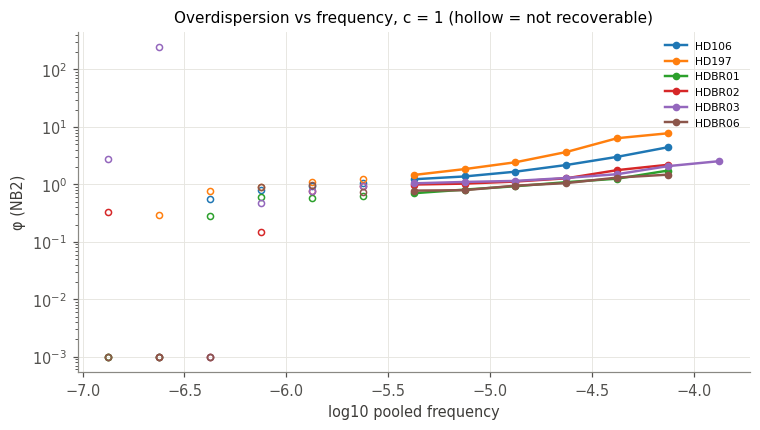

In [4]:
DONORS_RUN = [p for p in d_qc['patient'].unique()]       # start with one donor
real, calib = [], {}
for p in DONORS_RUN:
    g = d_qc[d_qc['patient'] == p]
    e = phi_by_bin(g, c=1, min_detect=2); e['donor'] = short(p); real.append(e)
    calib[p] = calibrate(g, n_rep=5, c=1, min_detect=2)
real = pd.concat(real, ignore_index=True)

# a bin is trusted only if it is trusted in every donor's calibration
flags = pd.concat({short(p): trusted_bins(cal)[1] for p, cal in calib.items()}, axis=1)
trusted = flags.all(axis=1)
print(trusted.to_string())

# plot: real estimates, untrusted bins hollow
fig, ax = plt.subplots(figsize=(7, 4))
for donor, e in real.groupby('donor'):
    ok = e['bin'].map(trusted).fillna(False).astype(bool)
    l, = ax.plot(e.loc[ok, 'log10f'], e.loc[ok, 'phi'], 'o-', ms=4, label=donor)
    ax.plot(e.loc[~ok, 'log10f'], e.loc[~ok, 'phi'], 'o', ms=4, mfc='none', color=l.get_color())
ax.set(yscale='log', xlabel='log10 pooled frequency', ylabel='φ (NB2)',
       title='Overdispersion vs frequency, c = 1 (hollow = not recoverable)')
ax.legend(fontsize=7); fig.tight_layout()

# trend on trusted bins, weighted by the simulated spread of log phi
sd = pd.concat({short(p): trusted_bins(cal)[2] for p, cal in calib.items()}, axis=1).median(axis=1)
t = real[real['bin'].map(trusted).fillna(False).astype(bool)].dropna(subset=['phi'])
w = 1 / t['bin'].map(sd).astype(float)
b, a = np.polyfit(t['log10f'].astype(float), np.log(t['phi']), 1, w=w)
print(f"log phi = {a:.2f} + {b:.3f}·log10 f   (b = 0 means no frequency dependence)")

In [5]:
per = []
for donor, e in t.groupby('donor'):
    w_d = 1 / e['bin'].map(sd).astype(float)
    b_d, a_d = np.polyfit(e['log10f'].astype(float), np.log(e['phi']), 1, w=w_d)
    per.append({'donor': donor, 'a': a_d, 'b': b_d, 'n_bins': len(e)})
per = pd.DataFrame(per)
print(per.round(3).to_string())
print("slope across donors: mean %.3f, sd %.3f" % (per['b'].mean(), per['b'].std(ddof=1)))

    donor      a      b  n_bins
0   HD106  4.755  0.856       6
1   HD197  7.398  1.316       6
2  HDBR01  2.940  0.615       6
3  HDBR02  2.536  0.482       6
4  HDBR03  2.110  0.391       7
5  HDBR06  2.307  0.482       6
slope across donors: mean 0.690, sd 0.347


## 2.4 Validation of the procedure: Which methods recovers $\phi$ more accurately?
We will use simuulated data with a known $\phi$ to determine which methods more accurately recovers the true value.

In [12]:
df_call = d_qc.assign(c_t=1)

In [13]:
from tcr_pipeline import simulate

SIM_DONORS = ['HD106_SEQTR', 'HDBR03_SEQTR_ReSeq', 'HDBR06_SEQTR_ReSeq']
SIM_PHI = [1.0, 1.6, 3.0]

# %% [markdown]
# ### 2.4a Clone frequencies copied from the donor
#
# Two scenarios:
#
# * **neutral**: every clone has a constant frequency (the estimator's assumption);
# * **5 % changing clones**: 5 % of the clones follow a log-linear trend of 2–30-fold over
#   the series. The estimator assumes constant frequencies, so it can only read these
#   changes as noise; the question is in which direction, and by how much, $\phi$ moves.
#
# Three estimators are compared: the one used (truncated, Cox–Reid), the same without
# truncation, and the same without Cox–Reid.

# %%
def phi_global(g, truncate=True, cox_reid=True):
    """One phi for all clones of g: truncated, Cox-Reid, clones >= 10x the cutoff."""
    return nb.fit_nb_dispersion_cr(g, min_detect=2, min_freq_mult=10, truncate=truncate,
                                   c_col='c_t', cox_reid=cox_reid, n_bins=1,
                                   min_bin_clones=10**9)['phi']
rows = []
for p in SIM_DONORS:
    g = d_qc[d_qc['patient'] == p]
    for phi_true in SIM_PHI:
        Nt = nb.estimate_dropout_N(g, phi=phi_true)
        for scen, frac in [('neutral', 0.0), ('5 % changing clones', 0.05)]:
            sim, _ = simulate.simulate_like_patient(g, phi_true, Nt, frac_spike=frac, seed=11)
            for name, kw in [('truncated + Cox-Reid (used)', {}),
                             ('not truncated', dict(truncate=False)),
                             ('no Cox-Reid', dict(cox_reid=False))]:
                if scen != 'neutral' and name != 'truncated + Cox-Reid (used)':
                    continue
                rows.append({'donor design': short(p), 'phi_true': phi_true,
                             'scenario': scen, 'estimator': name,
                             'phi_hat': phi_global(sim, **kw)})
simres = pd.DataFrame(rows)
simres['phi_hat / phi_true'] = simres['phi_hat'] / simres['phi_true']
display(simres.pivot_table(index=['scenario', 'estimator'], columns='phi_true',
                           values='phi_hat / phi_true', aggfunc=['min', 'max']).round(2))

# %%
fig, ax = plt.subplots(figsize=(7.2, 3.8))
styles = {('neutral', 'truncated + Cox-Reid (used)'): ('#2a78d6', 'o'),
          ('neutral', 'not truncated'): ('#eb6834', 's'),
          ('neutral', 'no Cox-Reid'): ('#8a8984', '^'),
          ('5 % changing clones', 'truncated + Cox-Reid (used)'): ('#1baf7a', 'D')}
for k, ((scen, name), (col, mk)) in enumerate(styles.items()):
    s = simres[(simres['scenario'] == scen) & (simres['estimator'] == name)]
    x = np.log(s['phi_true']) + (k - 1.5) * 0.045
    ax.scatter(x, s['phi_hat / phi_true'], color=col, marker=mk, s=34, edgecolor='white',
               linewidth=0.6, zorder=3, label=f'{name} — {scen}')
ax.axhline(1, color=INK, lw=1)
ax.axhspan(0.9, 1.1, color=GREY, alpha=0.12, lw=0)
ax.set(xticks=np.log(SIM_PHI), xticklabels=[str(v) for v in SIM_PHI], xlabel='true φ',
       ylabel='estimated / true φ', yscale='log',
       title='2.4a: recovery of a known φ (three donor designs per point group)')
ax.legend(fontsize=7.5, loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout()

KeyError: "Columns not found: 'c_t'"